# 05 — Two-Branch PPG + IMU Sensor Fusion Model

This notebook tests a more structured Deep Learning fusion strategy.

Instead of sending PPG and accelerometer channels directly into the same CNN from the first layer, the model uses two separate branches:

```text
PPG ----------------> PPG CNN branch ----\
                                      Fusion --> HR
ACC_X/Y/Z ----------> IMU CNN branch ----/
```

## Why test this?
PPG and accelerometer signals have different physical meanings.

- PPG branch learns pulse-related temporal patterns.
- IMU branch learns motion-related temporal patterns.
- Learned features are fused only after separate feature extraction.

## Fair comparison
This experiment uses exactly the same:
- recordings
- exact 8-second windows
- 320 model points
- chronological train / validation / test split
- chest-HR target
- timing QC

Nothing is saved to disk.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run the Final Preprocessing Pipeline

`02_preprocessing_windowing.ipynb` is executed in the same namespace so this model uses the exact same windows and splits as the previous experiments.

In [2]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Prepare Separate PPG and IMU Inputs

In [4]:
X_ppg_train_tb = X_fusion_train[:, :, 0:1]
X_ppg_val_tb = X_fusion_val[:, :, 0:1]
X_ppg_test_tb = X_fusion_test[:, :, 0:1]

X_imu_train_tb = X_fusion_train[:, :, 1:4]
X_imu_val_tb = X_fusion_val[:, :, 1:4]
X_imu_test_tb = X_fusion_test[:, :, 1:4]

print("PPG")
print("Train:", X_ppg_train_tb.shape)
print("Val  :", X_ppg_val_tb.shape)
print("Test :", X_ppg_test_tb.shape)

print()
print("IMU")
print("Train:", X_imu_train_tb.shape)
print("Val  :", X_imu_val_tb.shape)
print("Test :", X_imu_test_tb.shape)

assert X_ppg_train_tb.shape[1:] == (320, 1)
assert X_imu_train_tb.shape[1:] == (320, 3)

print()
print("Two-branch input shapes are correct.")

PPG
Train: (1322, 320, 1)
Val  : (281, 320, 1)
Test : (292, 320, 1)

IMU
Train: (1322, 320, 3)
Val  : (281, 320, 3)
Test : (292, 320, 3)

Two-branch input shapes are correct.


## 4. Training-Only Normalization

Each signal group is normalized using statistics calculated from the training set only.

- PPG: one training mean and standard deviation
- IMU: separate training mean and standard deviation for X, Y, Z

Validation and test sets use those same training statistics.

In [5]:
ppg_mean = X_ppg_train_tb.mean(
    axis=(0, 1),
    keepdims=True
)

ppg_std = X_ppg_train_tb.std(
    axis=(0, 1),
    keepdims=True
)

imu_mean = X_imu_train_tb.mean(
    axis=(0, 1),
    keepdims=True
)

imu_std = X_imu_train_tb.std(
    axis=(0, 1),
    keepdims=True
)

if np.any(ppg_std == 0) or np.any(imu_std == 0):
    raise ValueError(
        "At least one training channel has zero standard deviation."
    )

X_ppg_train_norm = (
    X_ppg_train_tb - ppg_mean
) / ppg_std

X_ppg_val_norm = (
    X_ppg_val_tb - ppg_mean
) / ppg_std

X_ppg_test_norm = (
    X_ppg_test_tb - ppg_mean
) / ppg_std

X_imu_train_norm = (
    X_imu_train_tb - imu_mean
) / imu_std

X_imu_val_norm = (
    X_imu_val_tb - imu_mean
) / imu_std

X_imu_test_norm = (
    X_imu_test_tb - imu_mean
) / imu_std


normalization_table = pd.DataFrame({
    "Channel": [
        "PPG_Raw",
        "ACC_X",
        "ACC_Y",
        "ACC_Z",
    ],
    "Train_Mean": [
        float(ppg_mean.reshape(-1)[0]),
        *imu_mean.reshape(-1).tolist(),
    ],
    "Train_Std": [
        float(ppg_std.reshape(-1)[0]),
        *imu_std.reshape(-1).tolist(),
    ],
})

display(
    normalization_table.round(5)
)

,Channel,Train_Mean,Train_Std
0,PPG_Raw,4475.98584,1247.35583
1,ACC_X,-0.32539,0.55772
2,ACC_Y,0.34338,0.23384
3,ACC_Z,-0.67551,0.31986


## 5. Reproducibility

In [6]:
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 6. Build the Two-Branch Model

### PPG branch
Learns temporal waveform features from PPG.

### IMU branch
Learns motion-related temporal features from the three accelerometer axes.

### Fusion head
Concatenates both learned representations and predicts one HR value.

In [7]:
def build_two_branch_model():
    # -------------------------
    # PPG branch
    # -------------------------
    ppg_input = tf.keras.layers.Input(
        shape=(320, 1),
        name="ppg_input"
    )

    p = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        activation="relu"
    )(ppg_input)

    p = tf.keras.layers.BatchNormalization()(p)

    p = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(p)

    p = tf.keras.layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(p)

    p = tf.keras.layers.BatchNormalization()(p)

    p = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(p)

    p = tf.keras.layers.Conv1D(
        96,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(p)

    p = tf.keras.layers.GlobalAveragePooling1D()(p)

    p = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(p)

    # -------------------------
    # IMU branch
    # -------------------------
    imu_input = tf.keras.layers.Input(
        shape=(320, 3),
        name="imu_input"
    )

    m = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        activation="relu"
    )(imu_input)

    m = tf.keras.layers.BatchNormalization()(m)

    m = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(m)

    m = tf.keras.layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(m)

    m = tf.keras.layers.BatchNormalization()(m)

    m = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(m)

    m = tf.keras.layers.Conv1D(
        96,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(m)

    m = tf.keras.layers.GlobalAveragePooling1D()(m)

    m = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(m)

    # -------------------------
    # Feature fusion
    # -------------------------
    fused = tf.keras.layers.Concatenate(
        name="feature_fusion"
    )([p, m])

    fused = tf.keras.layers.Dropout(
        0.30
    )(fused)

    fused = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(fused)

    fused = tf.keras.layers.Dropout(
        0.20
    )(fused)

    output = tf.keras.layers.Dense(
        1,
        name="predicted_hr"
    )(fused)

    model = tf.keras.Model(
        inputs=[
            ppg_input,
            imu_input,
        ],
        outputs=output,
        name="Two_Branch_PPG_IMU_Fusion"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


two_branch_model = build_two_branch_model()
two_branch_model.summary()

Model: "Two_Branch_PPG_IMU_Fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ppg_input           │ (None, 320, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imu_input           │ (None, 320, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 320, 32)   │        256 │ ppg_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 320, 32)   │        704 │ imu_input[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 320, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 320, 32)   │        128 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 80, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 80, 96)    │     18,528 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 80, 96)    │     18,528 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ conv1d_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ conv1d_5[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      6,208 │ global_average_p

 Total params: 80,129 (313.00 KB)

 Trainable params: 79,745 (311.50 KB)

 Non-trainable params: 384 (1.50 KB)

## 7. Training Callbacks

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 8. Train the Two-Branch Model

In [9]:
history = two_branch_model.fit(
    [
        X_ppg_train_norm,
        X_imu_train_norm,
    ],
    y_train,

    validation_data=(
        [
            X_ppg_val_norm,
            X_imu_val_norm,
        ],
        y_val
    ),

    epochs=180,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 4843.9810 - mae: 59.8175 - val_loss: 5742.0493 - val_mae: 72.8411 - learning_rate: 0.0010
Epoch 2/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 470.9682 - mae: 17.0628 - val_loss: 4157.9507 - val_mae: 62.0969 - learning_rate: 0.0010
Epoch 3/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 354.8541 - mae: 14.8167 - val_loss: 3064.1086 - val_mae: 53.3967 - learning_rate: 0.0010
Epoch 4/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 339.9314 - mae: 14.3565 - val_loss: 2308.7581 - val_mae: 46.2068 - learning_rate: 0.0010
Epoch 5/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 324.2673 - mae: 13.7900 - val_loss: 1509.7445 - val_mae: 37.3449 - learning_rate: 0.0010
Epoch 6/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 295.2878 - mae: 13.5753 - val_loss: 1172.3138 - val_mae: 32.8095 - learning_rate: 0.0010
Epoch 7/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 309.2216 - mae: 13.6233 - val_loss: 549.5040 -

## 9. Training History

Epochs trained: 55
Best epoch    : 37


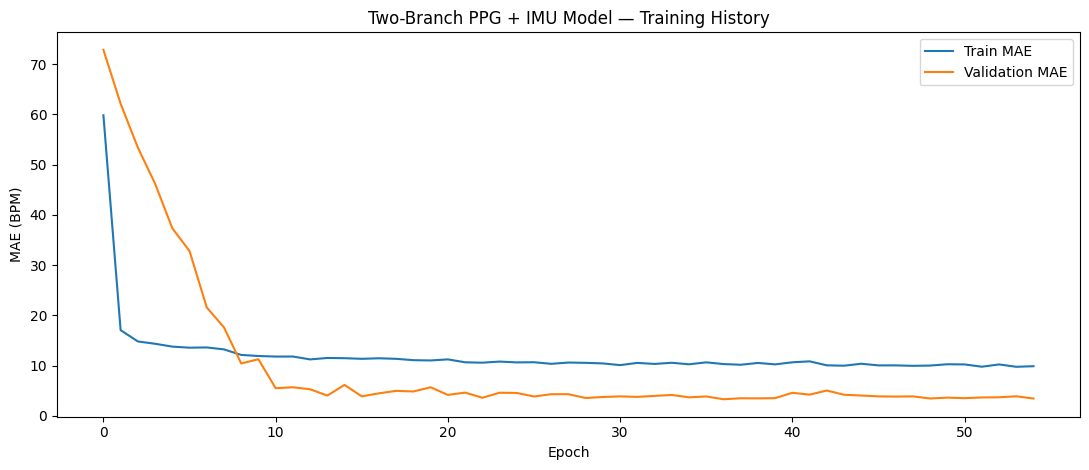

In [10]:
history_df = pd.DataFrame(
    history.history
)

best_epoch = int(
    history_df["val_loss"].idxmin()
    + 1
)

print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))

plt.plot(
    history_df["mae"],
    label="Train MAE"
)

plt.plot(
    history_df["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE (BPM)")
plt.title(
    "Two-Branch PPG + IMU Model — Training History"
)

plt.legend()
plt.tight_layout()
plt.show()

## 10. Test Predictions

In [11]:
y_pred_two_branch = (
    two_branch_model.predict(
        [
            X_ppg_test_norm,
            X_imu_test_norm,
        ],
        verbose=0
    )
    .reshape(-1)
)

print(
    "Two-branch predictions:",
    y_pred_two_branch.shape
)

Two-branch predictions: (292,)


## 11. Metric Function

In [12]:
def regression_metrics(
    y_true,
    y_prediction
):
    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_prediction = np.asarray(
        y_prediction,
        dtype=float
    )

    mae = mean_absolute_error(
        y_true,
        y_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_prediction
        )
    )

    r2 = r2_score(
        y_true,
        y_prediction
    )

    if (
        len(y_true) > 1
        and np.std(y_true) > 0
        and np.std(y_prediction) > 0
    ):
        correlation = np.corrcoef(
            y_true,
            y_prediction
        )[0, 1]
    else:
        correlation = np.nan

    return {
        "MAE_BPM": mae,
        "RMSE_BPM": rmse,
        "R2": r2,
        "Correlation": correlation,
        "True_Mean": np.mean(y_true),
        "True_Std": np.std(y_true),
        "Pred_Mean": np.mean(y_prediction),
        "Pred_Std": np.std(y_prediction),
    }

## 12. Overall Two-Branch Test Metrics

In [13]:
two_branch_overall_metrics = regression_metrics(
    y_test,
    y_pred_two_branch
)

overall_results = pd.DataFrame([
    {
        "Model": "Two-Branch PPG + IMU",
        **two_branch_overall_metrics,
    }
])

display(
    overall_results.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Two-Branch PPG + IMU,4.248,6.799,0.917,0.959,89.163,23.663,89.797,23.673


## 13. Global Mean Baseline

In [14]:
global_mean_hr = float(
    np.mean(y_train)
)

global_mean_pred = np.full(
    len(y_test),
    global_mean_hr,
    dtype=float
)

global_mean_metrics = regression_metrics(
    y_test,
    global_mean_pred
)

## 14. Activity-Mean Diagnostic Baseline

This is only a diagnostic baseline. It intentionally uses activity labels and therefore is not a deployable HR estimator.

In [15]:
train_activity = (
    meta_train[
        "Activity"
    ]
    .to_numpy()
)

test_activity = (
    meta_test[
        "Activity"
    ]
    .to_numpy()
)

activity_mean_map = {}

for activity in ACTIVITY_ORDER:
    mask = (
        train_activity
        == activity
    )

    if np.any(mask):
        activity_mean_map[
            activity
        ] = float(
            np.mean(
                y_train[mask]
            )
        )


activity_mean_pred = np.array(
    [
        activity_mean_map[
            activity
        ]
        for activity in test_activity
    ],
    dtype=float
)

activity_mean_metrics = regression_metrics(
    y_test,
    activity_mean_pred
)

diagnostic_table = pd.DataFrame([
    {
        "Model": "Global train-mean baseline",
        **global_mean_metrics,
    },
    {
        "Model": "Activity-mean diagnostic",
        **activity_mean_metrics,
    },
    {
        "Model": "Two-Branch PPG + IMU",
        **two_branch_overall_metrics,
    },
])

display(
    diagnostic_table.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Global train-mean baseline,21.293,23.836,-0.015,NaN,89.163,23.663,92.031,0.000
1,Activity-mean diagnostic,4.316,6.604,0.922,0.969,89.163,23.663,92.130,23.872
2,Two-Branch PPG + IMU,4.248,6.799,0.917,0.959,89.163,23.663,89.797,23.673


## 15. Per-Activity Two-Branch Metrics

In [16]:
activity_rows = []

for activity in ACTIVITY_ORDER:
    mask = (
        test_activity
        == activity
    )

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        y_pred_two_branch[mask]
    )

    activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(
            mask.sum()
        ),
        **metrics,
    })


two_branch_activity_results = pd.DataFrame(
    activity_rows
)

display(
    two_branch_activity_results.round(3)
)

,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,10.135,14.027,-7.134,0.415,84.915,4.918,90.981,13.869
1,High_Tempo_Cycling,38,9.231,11.883,-0.459,-0.345,113.883,9.839,115.901,3.806
2,Low_Tempo_Cycling,56,5.095,6.563,-1.953,-0.329,112.126,3.819,115.123,3.336
3,Sitting,43,3.492,5.141,0.473,0.770,72.895,7.079,74.121,7.567
4,Sleep,73,1.352,1.598,-0.616,0.317,56.056,1.257,56.943,0.985
5,Walking,74,3.706,6.176,-3.110,0.002,101.662,3.046,98.616,4.430


## 16. Macro Within-Activity Metrics

In [17]:
macro_mae = float(
    two_branch_activity_results[
        "MAE_BPM"
    ].mean()
)

macro_rmse = float(
    two_branch_activity_results[
        "RMSE_BPM"
    ].mean()
)

macro_corr = float(
    two_branch_activity_results[
        "Correlation"
    ].mean()
)

print(
    f"Macro activity MAE        : "
    f"{macro_mae:.3f} BPM"
)

print(
    f"Macro activity RMSE       : "
    f"{macro_rmse:.3f} BPM"
)

print(
    f"Macro activity correlation: "
    f"{macro_corr:.3f}"
)

Macro activity MAE        : 5.502 BPM
Macro activity RMSE       : 7.565 BPM
Macro activity correlation: 0.138


## 17. Activity-Mean vs Two-Branch MAE

In [18]:
baseline_rows = []

for activity in ACTIVITY_ORDER:
    mask = (
        test_activity
        == activity
    )

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        activity_mean_pred[mask]
    )

    baseline_rows.append({
        "Activity": activity,
        "Activity_Mean_MAE": metrics[
            "MAE_BPM"
        ],
    })


activity_baseline_results = pd.DataFrame(
    baseline_rows
)

comparison = (
    activity_baseline_results
    .merge(
        two_branch_activity_results[
            [
                "Activity",
                "MAE_BPM",
                "Correlation",
            ]
        ].rename(
            columns={
                "MAE_BPM": "Two_Branch_MAE",
                "Correlation": "Two_Branch_Correlation",
            }
        ),
        on="Activity"
    )
)

comparison[
    "Improvement_vs_ActivityMean_BPM"
] = (
    comparison[
        "Activity_Mean_MAE"
    ]
    - comparison[
        "Two_Branch_MAE"
    ]
)

display(
    comparison.round(3)
)

,Activity,Activity_Mean_MAE,Two_Branch_MAE,Two_Branch_Correlation,Improvement_vs_ActivityMean_BPM
0,Eating,4.353,10.135,0.415,-5.782
1,High_Tempo_Cycling,10.750,9.231,-0.345,1.519
2,Low_Tempo_Cycling,3.521,5.095,-0.329,-1.574
3,Sitting,5.516,3.492,0.770,2.024
4,Sleep,2.872,1.352,0.317,1.520
5,Walking,2.336,3.706,0.002,-1.370


## 18. Ground Truth vs Two-Branch Prediction

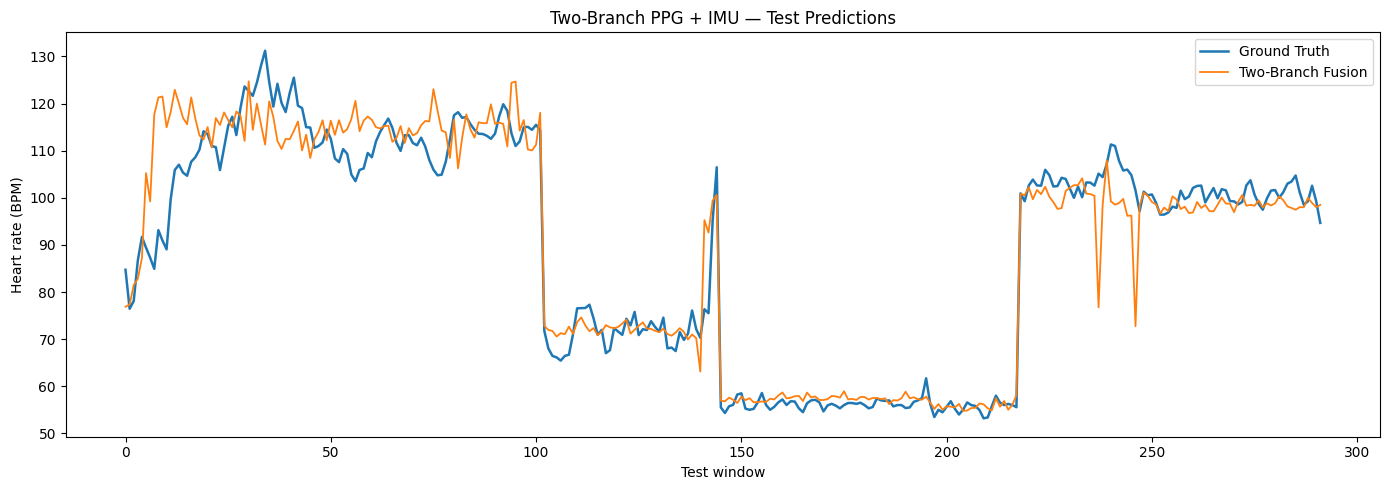

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test,
    label="Ground Truth",
    linewidth=1.8
)

plt.plot(
    y_pred_two_branch,
    label="Two-Branch Fusion",
    linewidth=1.3
)

plt.xlabel("Test window")
plt.ylabel("Heart rate (BPM)")

plt.title(
    "Two-Branch PPG + IMU — Test Predictions"
)

plt.legend()
plt.tight_layout()
plt.show()

## 19. Predicted vs True HR

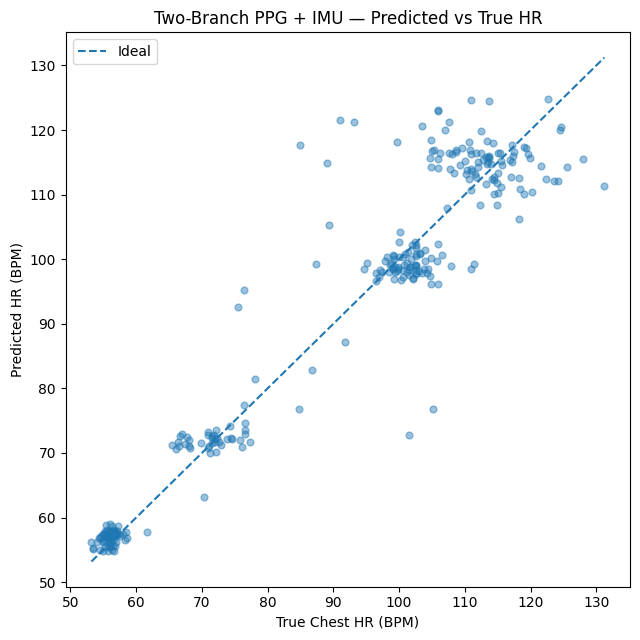

In [20]:
low = float(
    min(
        y_test.min(),
        y_pred_two_branch.min()
    )
)

high = float(
    max(
        y_test.max(),
        y_pred_two_branch.max()
    )
)

plt.figure(figsize=(6.5, 6.5))

plt.scatter(
    y_test,
    y_pred_two_branch,
    s=24,
    alpha=0.45
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel("True Chest HR (BPM)")
plt.ylabel("Predicted HR (BPM)")

plt.title(
    "Two-Branch PPG + IMU — Predicted vs True HR"
)

plt.legend()
plt.tight_layout()
plt.show()

## 20. Per-Activity MAE

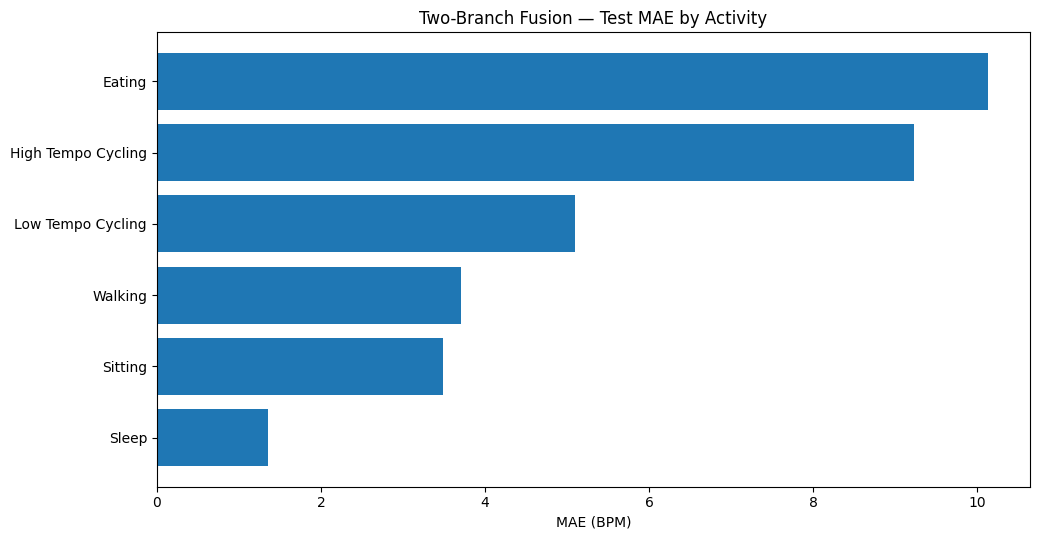

In [21]:
plot_df = two_branch_activity_results.sort_values(
    "MAE_BPM"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "MAE_BPM"
    ]
)

plt.xlabel("MAE (BPM)")
plt.title(
    "Two-Branch Fusion — Test MAE by Activity"
)

plt.tight_layout()
plt.show()

## 21. Per-Activity Correlation

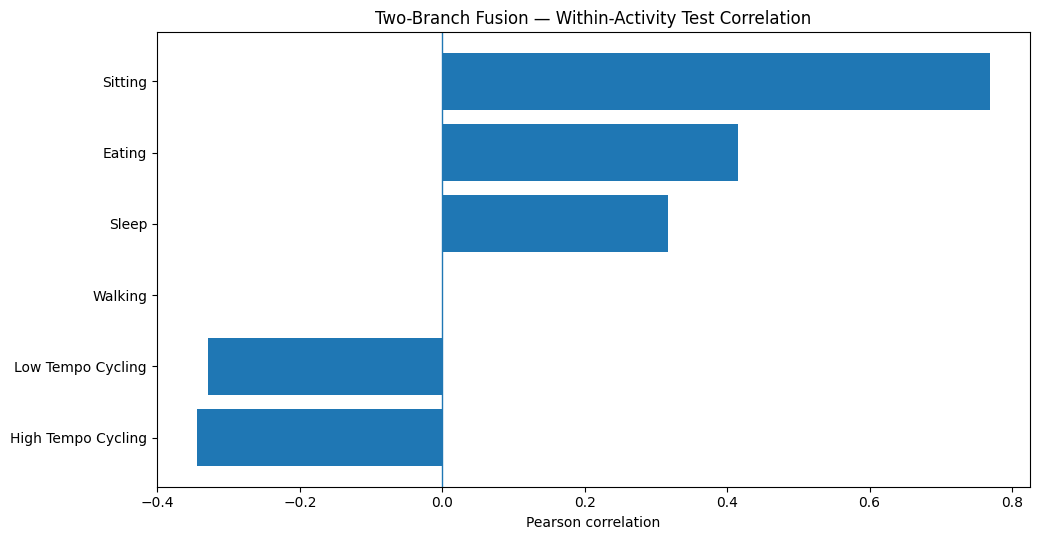

In [22]:
plot_df = two_branch_activity_results.sort_values(
    "Correlation"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "Correlation"
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Pearson correlation")

plt.title(
    "Two-Branch Fusion — Within-Activity Test Correlation"
)

plt.tight_layout()
plt.show()

## 22. Activity-Mean Baseline vs Two-Branch Fusion

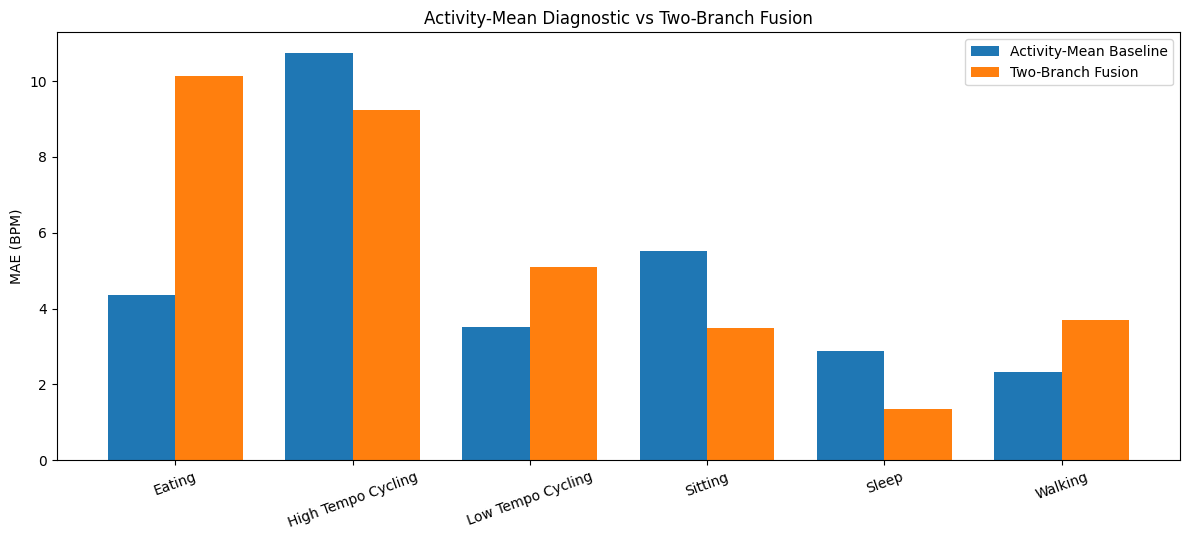

In [23]:
x = np.arange(
    len(comparison)
)

width = 0.38

plt.figure(figsize=(12, 5.5))

plt.bar(
    x - width / 2,
    comparison[
        "Activity_Mean_MAE"
    ],
    width,
    label="Activity-Mean Baseline"
)

plt.bar(
    x + width / 2,
    comparison[
        "Two_Branch_MAE"
    ],
    width,
    label="Two-Branch Fusion"
)

plt.xticks(
    x,
    comparison[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    rotation=20
)

plt.ylabel("MAE (BPM)")

plt.title(
    "Activity-Mean Diagnostic vs Two-Branch Fusion"
)

plt.legend()
plt.tight_layout()
plt.show()

## 23. No Saving

This notebook intentionally writes nothing to disk.

No:
- model file
- CSV
- NPZ
- PNG
- prediction file

is created.

## 24. What to Send for Review

After running the notebook, send:

1. training-history graph
2. overall two-branch metrics
3. diagnostic comparison table
4. per-activity metrics
5. macro activity metrics
6. activity-mean vs two-branch comparison
7. test prediction graph
8. per-activity correlation graph

Then we will directly compare:

- PPG-only CNN
- early-fusion PPG + IMU CNN
- two-branch PPG + IMU model
- activity-mean diagnostic